# 4. Sensitivity, budget size, fairness and pilot design

**Goal.** Test how the recommendation depends on the assumptions (offer cost and save rate above all), choose the campaign size, review fairness and customer experience, and size the pilot that will measure the real save rate.

Numbers in the text were generated for run `20261029T034118630540Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
pd.set_option("display.precision", 3)
run = latest_run()
print("Run:", run.name)

Run: 20261029T034118630540Z-88be4b93


## One assumption at a time

,label,low,high,base,net_low_retarget,net_high_retarget,net_low_fixed,net_high_fixed
0,Save rate of the standard offer,0.10,0.30,0.20,458.467,6359.368,-469.236,5805.643
1,Value horizon (months),6.00,18.00,12.00,89.471,5521.513,-336.206,5521.513
2,Offer cost (multiplier on catalog cost),0.50,1.50,1.00,6061.399,1197.802,4035.703,1300.703
3,Contribution margin,0.20,0.40,0.30,614.221,4724.271,612.136,4724.271
4,Contact cost per customer (USD),1.00,10.00,5.00,3842.777,1851.854,3280.203,1903.203
5,Annual discount rate,0.05,0.15,0.10,2836.486,2513.349,2836.006,2513.349
6,"Tenure effect on remaining months (new 1-s, lo...",0.00,0.50,0.25,2972.619,3279.521,2427.233,2884.764


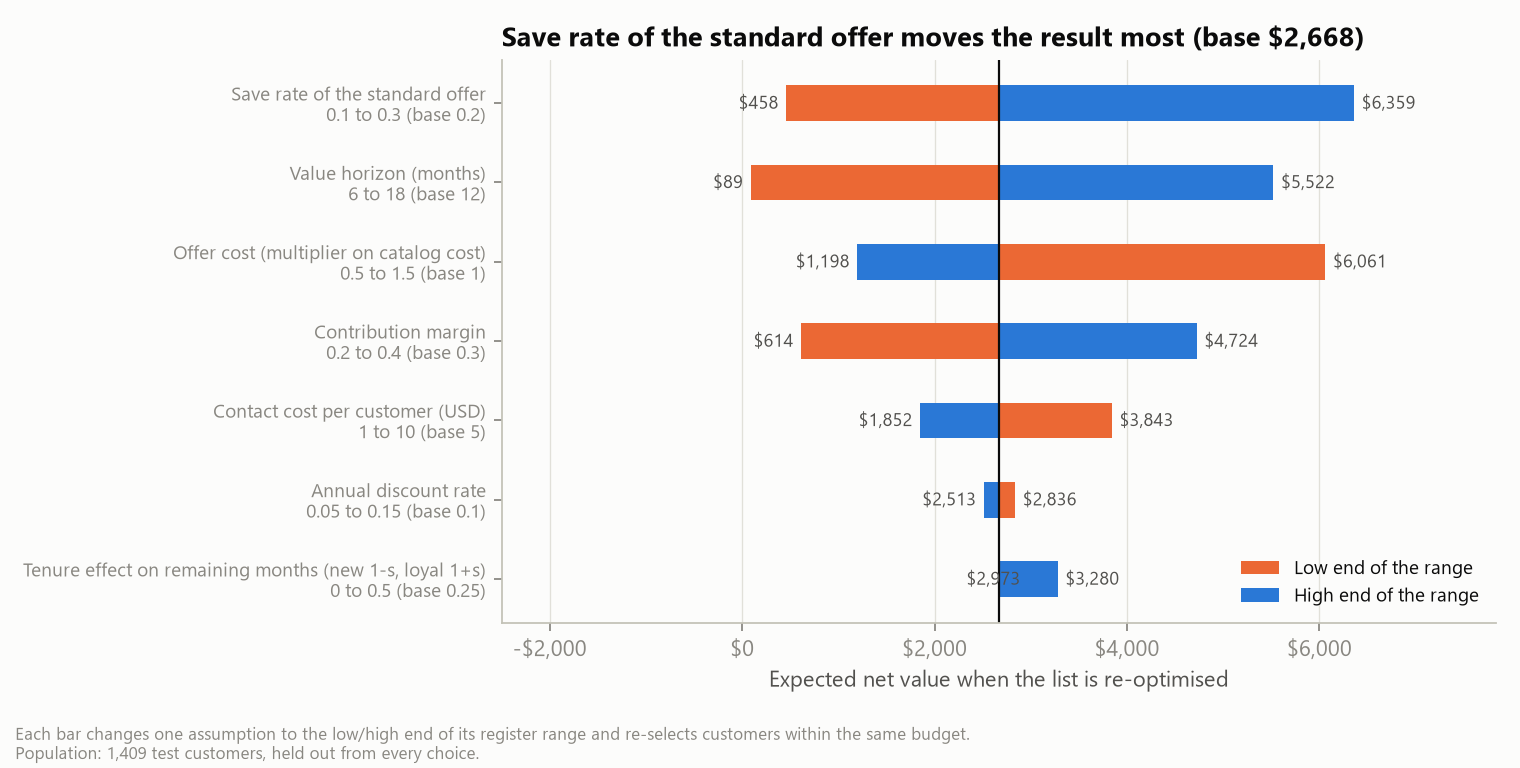

In [2]:
display(pd.read_csv(run / "tornado.csv")[["label", "low", "high", "base", "net_low_retarget", "net_high_retarget", "net_low_fixed", "net_high_fixed"]])
display(Image(filename=str(ROOT / "reports/figures/tornado.png")))

**Interpretation.** Save rate of the standard offer and value horizon (months) move the result most. *Retarget* re-selects customers under the new assumption; *fixed* keeps today's list. A re-optimised plan cannot go below zero (it would contact nobody), a frozen list can.

## Save rate x offer cost

cost_multiplier,0.50,0.75,1.00,1.25,1.50,2.00
fixed: save rate / cost x,,,,,,
0.05,-670.0,-1354.0,-2038.0,-2722.0,-3405.0,-4773.0
0.10,898.0,215.0,-469.0,-1153.0,-1837.0,-3204.0
0.15,2467.0,1783.0,1099.0,416.0,-268.0,-1636.0
0.20,4036.0,3352.0,2668.0,1984.0,1301.0,-67.0
0.25,5604.0,4921.0,4237.0,3553.0,2869.0,1502.0
0.30,7173.0,6489.0,5806.0,5122.0,4438.0,3071.0
0.40,10311.0,9627.0,8943.0,8259.0,7576.0,6208.0


cost_multiplier,0.50,0.75,1.00,1.25,1.50,2.00
retarget: save rate / cost x,,,,,,
0.05,1277.0,263.0,17.0,0.0,0.0,0.0
0.10,2865.0,1348.0,458.0,90.0,2.0,0.0
0.15,4459.0,2559.0,1423.0,662.0,213.0,0.0
0.20,6061.0,3914.0,2668.0,1815.0,1198.0,400.0
0.25,8054.0,5801.0,4412.0,3438.0,2694.0,1611.0
0.30,10457.0,7986.0,6359.0,5166.0,4244.0,2892.0
0.40,15784.0,12583.0,10327.0,8665.0,7375.0,5487.0


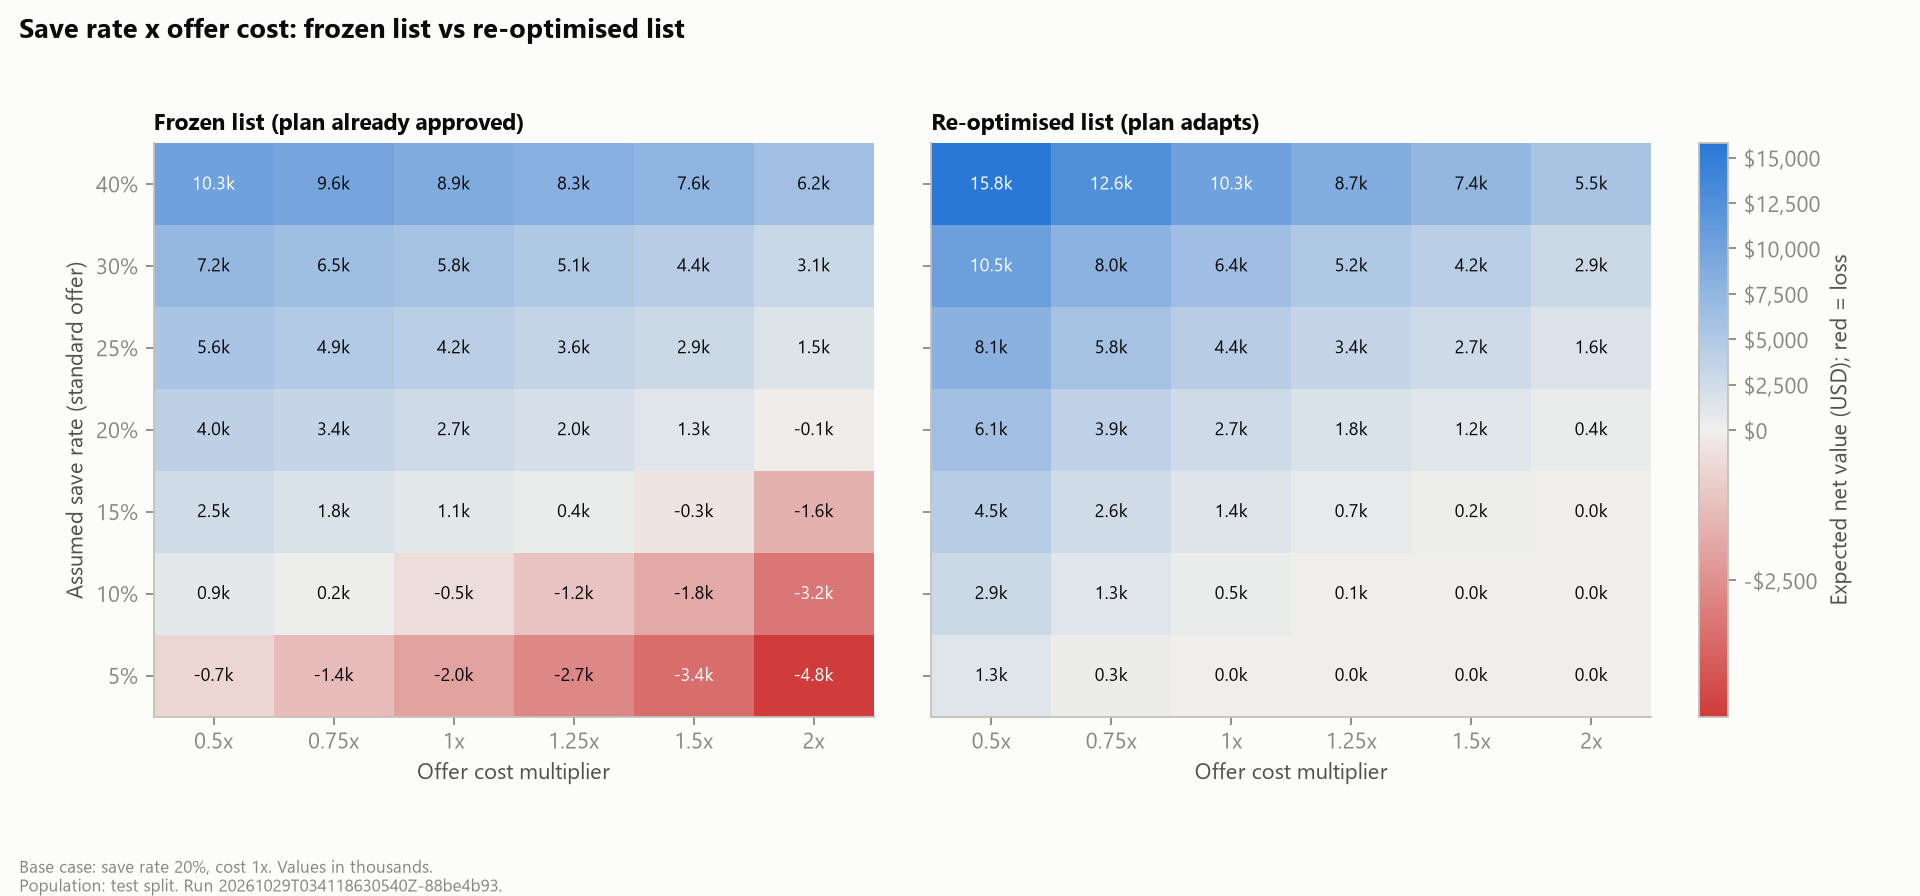

,scenario,overrides,selected_count,cost,expected_net_value,roi,expected_saved,fixed_expected_net_value,fixed_roi
0,pessimistic,"{""save_rate"": 0.1, ""offer_cost_multiplier"": 1....",0,0.0,0.000,NaN,0.000,-2723.693,-0.587
1,base,{},153,3500.0,2668.203,0.762,18.285,2668.203,0.762
2,optimistic,"{""save_rate"": 0.3, ""offer_cost_multiplier"": 0....",312,3499.5,19083.763,5.453,47.077,12958.498,5.497


{'strategy': 'segment_offers',
 'selected_count': 153,
 'save_rate_multiplier': 0.5674261751265909,
 'break_even_default_save_rate': 0.11348523502531818,
 'mix_save_rate': 0.1890445152849163,
 'break_even_mix_save_rate': 0.10726880623678041,
 'offer_cost_multiplier': 1.9755770711382157,
 'break_even_default_offer_cost': 39.51154142276431,
 'minimum_viable_save_rate': 0.0772983296172961,
 'break_even_probability_quantiles': {'p10': 0.2943546409333618,
  'p25': 0.36409404816988133,
  'p50': 0.5432991995188771,
  'p75': 1.0859460700643673,
  'p90': 1.832907746055055}}

,plan,kind,draws,mean,p05,p50,p95,prob_loss,prob_loss_se,mean_loss_if_loss,prob_gain
0,recommended,frozen list,5000,3996.834,-2444.027,3639.025,11531.556,0.174,0.005,-1831.487,NaN
1,base budget,frozen list,5000,2592.658,-468.727,2375.303,6282.219,0.090,0.004,-639.222,NaN
2,risk only,frozen list,5000,1241.224,-1266.976,1079.592,4304.072,0.244,0.006,-795.667,NaN
3,recommended (label-based),frozen list,5000,3231.255,-2900.032,2894.830,10351.915,0.222,0.006,-1890.299,NaN
4,"recommended, re-optimised for each draw",re-optimised,200,4722.749,276.859,4175.966,11515.314,0.000,0.000,0.000,NaN
5,value of knowing the assumptions (re-optimised...,difference,200,845.544,-63.286,560.242,2673.010,NaN,NaN,NaN,NaN
6,base-budget list minus risk-only list,difference,5000,1351.434,353.174,1240.425,2685.395,NaN,NaN,NaN,1.0


,parameter,spearman_with_recommended_net
0,value.base_horizon_months,0.592
1,save_rate,0.506
2,value.margin,0.420
3,offer_cost_multiplier,-0.361
4,contact_cost,-0.133
5,value.discount_rate_annual,-0.066
6,value.tenure_factor_spread,-0.005


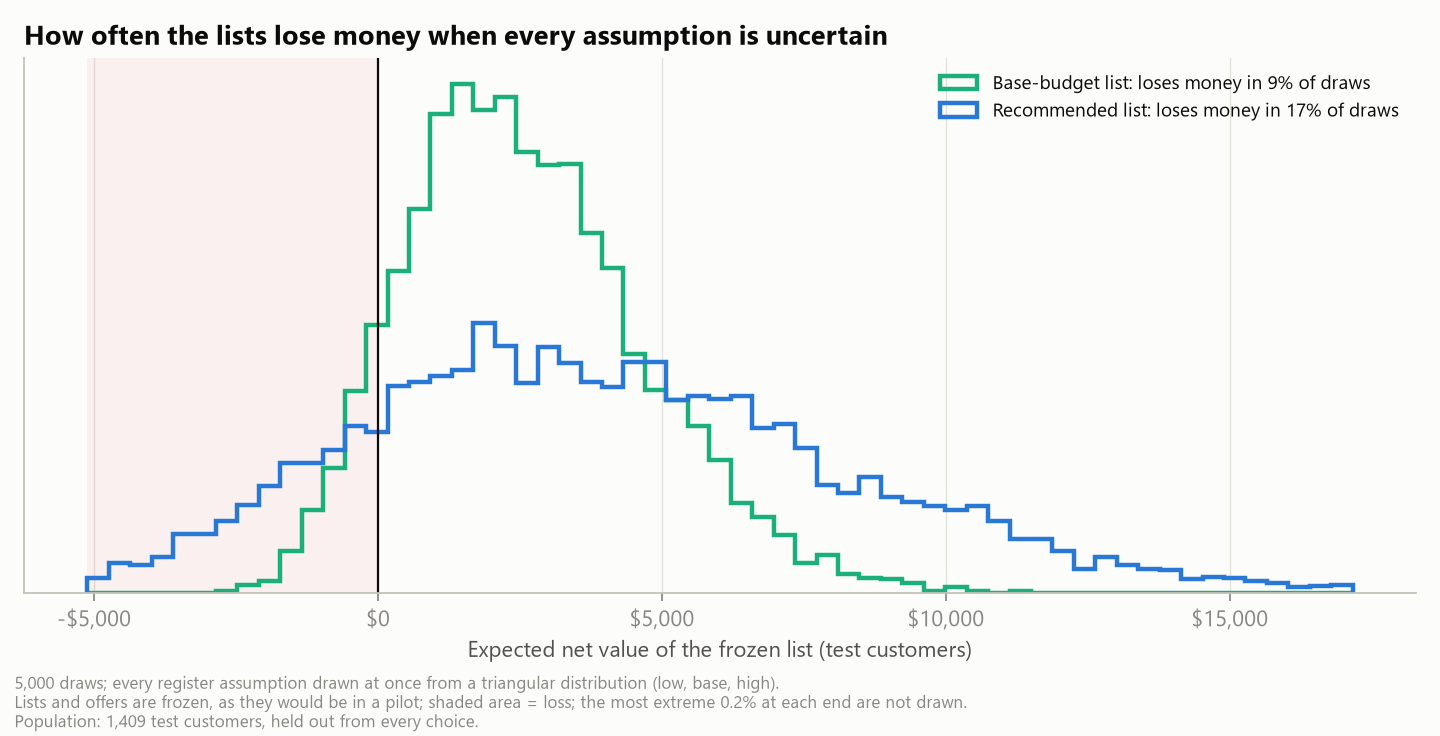

In [3]:
sens = pd.read_csv(run / "sensitivity.csv")
grid = sens.query("axis == 'save_rate x offer_cost'")
for mode in ["fixed", "retarget"]:
    display(grid.query("mode == @mode").pivot(index="parameter", columns="cost_multiplier", values="expected_net_value").round(0).rename_axis(f"{mode}: save rate / cost x"))
display(Image(filename=str(ROOT / "reports/figures/sensitivity_heatmap.png")))
display(pd.read_csv(run / "scenarios.csv"))
display(read_json(run / "break_even.json"))
display(pd.read_csv(run / "monte_carlo_summary.csv").round(3))
display(pd.read_csv(run / "monte_carlo_drivers.csv").round(3))
display(Image(filename=str(ROOT / "reports/figures/monte_carlo.png")))

**Interpretation.** Break-even save rate: 11.3% for the base-budget list and 13.8% for the larger recommended list; below 7.7% nobody has positive expected value. Re-optimised scenarios (pessimistic / base / optimistic): $0 / $2,668 / $19,084; a list frozen under pessimistic assumptions would make -$2,724. Drawing every assumption at once from its range (5,000 draws), the frozen recommended list loses money in 17% of draws and the base-budget list in 9%; the base-budget list beats the risk-only list in 100% of draws. Value horizon (months) and save rate of the standard offer drive the spread most.

## Budget optimisation across campaign sizes

,budget_share,selected_count,cost,expected_net_value,marginal_roi
0,0.00,0,0.0,0.000,NaN
1,0.02,38,700.0,809.864,1.157e+00
2,0.04,71,1400.0,1389.707,8.283e-01
3,0.06,99,2100.0,1867.985,6.833e-01
4,0.08,128,2800.0,2284.720,5.953e-01
5,0.10,152,3499.0,2651.004,5.240e-01
6,0.12,173,4225.0,2965.073,4.326e-01
7,0.14,193,4925.0,3217.205,3.602e-01
8,0.16,213,5625.0,3435.710,3.122e-01
9,0.18,241,6325.0,3612.443,2.525e-01


{'strategy': 'segment_offers',
 'population': 'validation',
 'hurdle_marginal_roi': 0.1,
 'recommended_share': 0.26,
 'recommended_budget': 9150.0,
 'expected_net_value': 4060.127834696843,
 'roi': 0.4437783183623175,
 'marginal_roi': 0.11207041641622818,
 'net_maximising_share': 0.32,
 'net_maximising_value': 4119.0842575037295}

{'strategy': 'segment_offers',
 'budget_share': 0.26,
 'budget': 9150.0,
 'selected_count': 324,
 'cost': 9150.0,
 'remaining_budget': 0.0,
 'expected_saved': 43.83673848887302,
 'expected_retained_value': 13295.399853261513,
 'expected_net_value': 4145.399853261513,
 'roi': 0.45304916429087577,
 'expected_precision': 0.5987633378055841,
 'precision_contacted': 0.5648148148148148,
 'label_based_simulated_net': 3377.0883710275048,
 'high_risk_high_value_count': 57,
 'high_risk_high_value_coverage': 1.0,
 'scenario_id': '56f776cb462c',
 'solver_status': 'optimal',
 'contacted_share': 0.22995031937544358,
 'break_even': {'selected_count': 324,
  'save_rate_multiplier': 0.6882079592179697,
  'break_even_default_save_rate': 0.13764159184359395,
  'mix_save_rate': 0.22596335987904503,
  'break_even_mix_save_rate': 0.15550978276039323,
  'offer_cost_multiplier': 1.5505179087996697,
  'break_even_default_offer_cost': 31.010358175993396}}

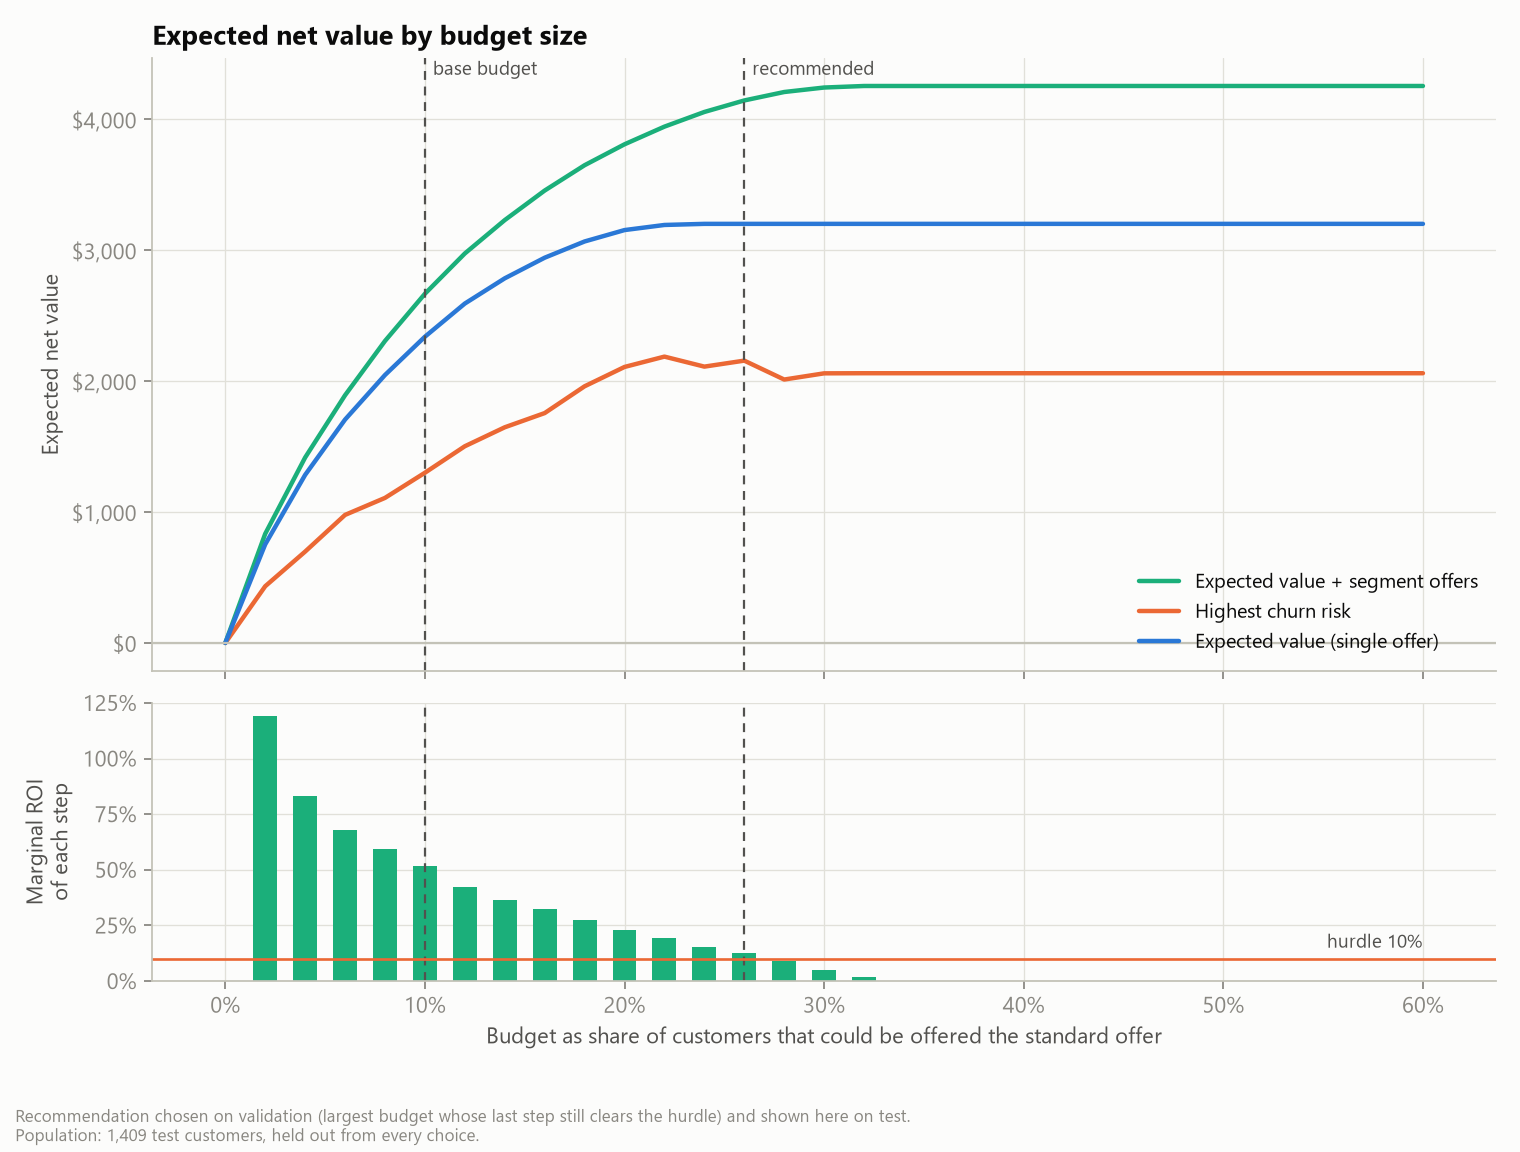

In [4]:
curve = pd.read_csv(run / "budget_curve.csv")
display(curve.query("population == 'validation'")[["budget_share", "selected_count", "cost", "expected_net_value", "marginal_roi"]])
display(read_json(run / "validation_decisions.json")["budget_recommendation"])
display(read_json(run / "recommended_campaign.json"))
display(Image(filename=str(ROOT / "reports/figures/profit_curve.png")))

**Interpretation.** On validation, the largest budget whose last step still earns 10% is the cost of the standard offer for 26% of customers. On test this buys 324 offers (23% of customers, because the optimiser mixes offers), $9,150 cost and $4,145 expected net value.

## Fairness and customer experience

,strategy,attribute,group,customers,selection_rate,ratio_to_reference,ratio_lower_95,ratio_upper_95,risk_adjusted_ratio,review_flag,explained_by_risk
0,risk,gender,Female,714,0.101,1.031,0.740,1.408,1.015,False,False
1,risk,gender,Male,695,0.098,1.000,1.000,1.000,1.000,False,False
2,risk,SeniorCitizen,0,1170,0.078,1.000,1.000,1.000,1.000,False,False
3,risk,SeniorCitizen,1,239,0.205,2.636,1.882,3.617,1.011,True,True
4,risk,tenure_segment,developing,204,0.108,1.085,0.700,1.503,1.119,False,False
5,risk,tenure_segment,loyal,774,0.006,0.065,0.013,0.126,1.007,True,True
6,risk,tenure_segment,new,431,0.262,2.639,2.398,2.910,1.109,True,True
7,risk,Contract,Month-to-month,786,0.178,1.793,1.718,1.879,1.250,True,False
8,risk,Contract,One year,284,0.000,0.000,0.000,0.000,0.000,True,False
9,risk,Contract,Two year,339,0.000,0.000,0.000,0.000,0.000,True,False


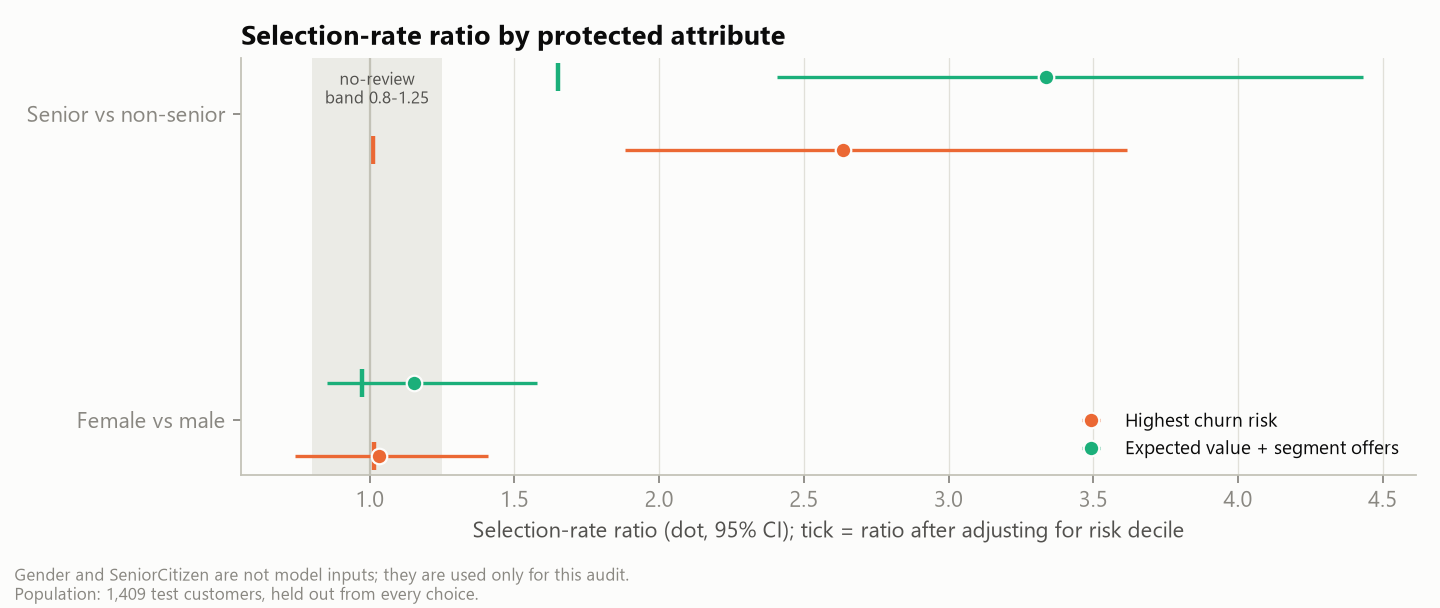

In [5]:
fair = pd.read_csv(run / "fairness.csv")
display(fair[["strategy", "attribute", "group", "customers", "selection_rate", "ratio_to_reference", "ratio_lower_95", "ratio_upper_95", "risk_adjusted_ratio", "review_flag", "explained_by_risk"]])
display(Image(filename=str(ROOT / "reports/figures/fairness.png")))

**Interpretation.** Seniors are contacted 3.34x as often as non-seniors; within the same risk decile the ratio is 1.65x. Risk explains most of the gap and value (higher bills) the rest. Neither gender nor age is a model input. Because an offer is both a discount and an intrusion, the gap is flagged for human review each wave rather than corrected mechanically.

## Pilot sizing

In [6]:
display(read_json(run / "pilot_plan.json"))
display(pd.read_csv(run / "pilot_power.csv"))

{'control_churn_expected': 0.5987633378055841,
 'observed_churn_test_list': 0.5648148148148148,
 'recommended_share': 0.26,
 'contacted_share': 0.22995031937544358,
 'base_population': 7043,
 'list_size_per_wave': 1620,
 'arm_size_per_wave': 810,
 'break_even_save_rate': 0.15550978276039323,
 'assumed_save_rate': 0.22596335987904503,
 'per_arm_break_even': 447.0,
 'minimum_detectable_save_rate_one_wave': 0.11524601062339812,
 'decision_rule': "go if the 95% interval of q is above 0 and q >= break-even; stop if q <= 0 or the interval is below break-even; otherwise extend (q = 1 - churn(offered) / churn(holdout), the list's mix save rate)",
 'alpha': 0.05,
 'power': 0.8,
 'holdout_share': 0.5,
 'outcome_window_days': 90}

,assumed_save_rate,is_break_even,is_assumed,control_churn,treated_churn,customers_per_arm,total_customers,arm_size_per_wave,waves_needed,p_go,p_extend,p_stop
0,0.050,False,False,0.599,0.569,4255.0,8510.0,810,6,0.003,0.224,7.726e-01
1,0.100,False,False,0.599,0.539,1073.0,2146.0,810,2,0.073,0.649,2.787e-01
2,0.150,False,False,0.599,0.509,480.0,960.0,810,1,0.446,0.527,2.635e-02
3,0.155,True,False,0.599,0.506,447.0,894.0,810,1,0.503,0.477,2.040e-02
4,0.200,False,False,0.599,0.479,271.0,542.0,810,1,0.878,0.121,4.000e-04
5,0.226,False,True,0.599,0.463,213.0,426.0,810,1,0.970,0.030,0.000e+00
6,0.300,False,False,0.599,0.419,121.0,242.0,810,1,1.000,0.000,0.000e+00


**So what.** One wave of 1,620 customers with half held out can detect a save rate of about 12% or more, below the recommended list's break-even of 15.6% (the average save rate of its offer mix, assumed 22.6%). If the true save rate is the assumed one, the decision rule says go after one wave 97% of the time. Measuring it is the decisive next step: it replaces the most influential assumption with evidence.